**LISTAS**

#Cargar datos

In [1]:
# Importar las librerías necesarias para manipulación de datos y JSON.
import pandas as pd
import numpy as np
import json

from pathlib import Path

def localizar_edas():
    """Busca Data/raw y Data/processed en Jupyter, Visual Studio Code y Colab.

    Orden de búsqueda: carpeta del notebook, directorio de trabajo y, en Colab, /content.
    Sirve con la estructura Data/raw y Data/processed, y también si los CSV de raw
    o de processed están sueltos en una de esas carpetas (en Colab, junto a sample_data).
    """
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }
    marcas_raw = (
        "artistainfo.json",
        "cancioninfo.json",
        "fecha.json",
        "favoritos.json",
        "listas.json",
        "popularidad.json",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )
    marcas_processed = (
        "cancion.csv",
        "cancion_ids.csv",
        "id_disco.csv",
        "id_genero.csv",
        "fecha_publicacion.csv",
        "fecha_limpio.csv",
        "artistas.csv",
        "artistas_ids.csv",
        "artistas_sql.csv",
        "id_artistas_sql.csv",
        "favoritos.csv",
        "favoritos_eda.csv",
        "listas_canciones.csv",
        "popularidad.csv",
        "features_30_sec.csv",
        "features_3_sec.csv",
    )

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    cwd = Path.cwd().resolve()
    if cwd not in bases:
        bases.append(cwd)
    content = Path("/content")
    if content.is_dir():
        content = content.resolve()
        if content not in bases:
            bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir() and drive not in bases:
            bases.append(drive)

    def buscar(nombre, marcas):
        opuesta = "processed" if nombre == "raw" else "raw"

        def tiene(carpeta):
            try:
                return any((carpeta / marca).is_file() for marca in marcas)
            except OSError:
                return False

        def nombrada(directorio):
            anidada = directorio / "Data" / nombre
            if tiene(anidada):
                return anidada
            if directorio.name == nombre and tiene(directorio):
                return directorio
            return None

        def hijos(directorio, profundidad, limite):
            if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
                return None
            try:
                entradas = list(directorio.iterdir())
            except OSError:
                return None
            for hijo in entradas:
                if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                    continue
                limite[0] -= 1
                hallazgo = nombrada(hijo)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
                hallazgo = hijos(hijo, profundidad - 1, limite)
                if hallazgo is not None:
                    return hallazgo
                if limite[0] <= 0:
                    return None
            return None

        for base in bases:
            if not base.is_dir():
                continue
            hallazgo = nombrada(base)
            if hallazgo is not None:
                return hallazgo
            for padre in list(base.parents)[:6]:
                hallazgo = nombrada(padre)
                if hallazgo is not None:
                    return hallazgo
            profundidad = 3 if base.name in {"content", "MyDrive"} else 2
            hallazgo = hijos(base, profundidad, [400])
            if hallazgo is not None:
                return hallazgo
            if base.name != opuesta and tiene(base):
                return base
        return None

    cruda = buscar("raw", marcas_raw)
    procesados = buscar("processed", marcas_processed)

    if cruda is None and procesados is None:
        raise FileNotFoundError(
            "No se encuentran los datos. "
            "Tiene que existir la carpeta Data/raw o Data/processed, "
            "o los CSV en la carpeta del notebook, en el directorio de trabajo "
            "o, en Colab, en /content junto a sample_data."
        )

    if cruda is not None and procesados is None:
        if cruda.name == "raw":
            procesados = cruda.parent / "processed"
        else:
            procesados = cruda
        procesados.mkdir(parents=True, exist_ok=True)
    elif procesados is not None and cruda is None:
        if procesados.name == "processed":
            cruda = procesados.parent / "raw"
        else:
            cruda = procesados

    return cruda, procesados
DATA_RAW, DATA_PROCESSED = localizar_edas()
print("Raw:", DATA_RAW)
print("Processed:", DATA_PROCESSED)

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)


In [2]:
# Cargar el archivo JSON
with open(DATA_RAW / "listas.json", "r", encoding="utf-8") as file:
    data = json.load(file)
data


{'blues.00000.wav': ['13_hkm-dak_53',
  '87_vio-pis_64',
  '74_ttp-exw_78',
  '84_kes-ggj_88',
  '65_vqt-xlw_66',
  '82_htj-okh_59',
  '55_xwo-wff_98',
  '19_mbc-yva_50'],
 'blues.00001.wav': ['86_yix-dsj_5',
  '10_rjh-xct_85',
  '2_kfr-ymg_66',
  '5_nxf-dxi_34',
  '11_jfr-myc_65',
  '73_ljj-eco_63',
  '86_xmk-fgu_15',
  '79_ygr-vvr_9',
  '57_xkm-xqh_34',
  '69_frc-mcn_38',
  '39_egw-ldv_63',
  '87_cvt-oaa_9',
  '54_ssp-qmn_57',
  '71_llj-gcf_46',
  '12_gld-rvg_93',
  '99_lvx-djf_55',
  '10_pso-cjf_32',
  '79_wds-jpq_12',
  '65_khd-yfo_70',
  '54_qyx-xpe_56',
  '7_udd-rfp_88',
  '71_yss-uxg_86',
  '48_aqt-fwx_90',
  '21_mxe-olc_6',
  '38_xdh-sld_68',
  '46_blv-uar_91',
  '93_pvr-nmh_86',
  '5_vos-cbi_32',
  '75_aeh-inr_75',
  '91_cfv-xyq_13',
  '36_khd-aak_60',
  '89_tot-skd_36',
  '41_uty-www_16',
  '86_pxa-xfw_19',
  '33_okv-rkt_90',
  '93_abr-srp_38',
  '99_ryc-guh_27',
  '72_jwf-yrs_27',
  '58_lip-hui_43',
  '78_xnh-bct_6',
  '8_ocx-uhm_36',
  '65_cfr-fxg_78',
  '76_nhq-hac_99',
  

In [3]:
# Se itera sobre cada canción y los usuarios que la tienen en listas para crear una lista de diccionarios.
rows = []
for cancion, lista in data.items():
    for item_str in lista:
        row_dict = {
            "nombre_archivo_cancion": cancion,
            "id_usuario_lista": item_str
        }
        rows.append(row_dict)

In [4]:
df_listas=pd.DataFrame(rows)
df_listas

,nombre_archivo_cancion,id_usuario_lista
0,blues.00000.wav,13_hkm-dak_53
1,blues.00000.wav,87_vio-pis_64
2,blues.00000.wav,74_ttp-exw_78
3,blues.00000.wav,84_kes-ggj_88
4,blues.00000.wav,65_vqt-xlw_66
...,...,...
50918,rock.00099.wav,84_spq-tob_81
50919,rock.00099.wav,19_bam-pep_6
50920,rock.00099.wav,58_asb-ffn_72
50921,rock.00099.wav,40_xyo-jwu_40


In [5]:

df_listas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50923 entries, 0 to 50922
Data columns (total 2 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   nombre_archivo_cancion  50923 non-null  object
 1   id_usuario_lista        50923 non-null  object
dtypes: object(2)
memory usage: 795.8+ KB


#Sustitución archivo canción por id canción fuionando df

In [6]:

df_cancion_id = pd.read_csv(DATA_PROCESSED / "cancion_ids.csv")


display(df_cancion_id.head())


,cancion,duracion,genero,disco,autor,id_cancion,id_genero,id_disco
0,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1
1,blues.00001.wav,00:02:22,blues,blues7,Sonny Boy Williamson,2,1,2
2,blues.00002.wav,00:01:36,blues,blues5,Muddy Waters,3,1,3
3,blues.00003.wav,00:01:51,blues,blues10,Freddie King,4,1,4
4,blues.00004.wav,00:03:11,blues,blues1,Memphis Minnie,5,1,5


In [7]:
df_listas_merged_final = pd.merge(
    df_listas,
    df_cancion_id,
    left_on='nombre_archivo_cancion',
    right_on='cancion',
    how='left'
)

print("Primeras 5 filas del DataFrame fusionado df_listas_merged_final:")
display(df_listas_merged_final.head(10))

print("Información del DataFrame fusionado df_listas_merged_final:")
df_listas_merged_final.info()

Primeras 5 filas del DataFrame fusionado df_listas_merged_final:


,nombre_archivo_cancion,id_usuario_lista,cancion,duracion,genero,disco,autor,id_cancion,id_genero,id_disco
0,blues.00000.wav,13_hkm-dak_53,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1
1,blues.00000.wav,87_vio-pis_64,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1
2,blues.00000.wav,74_ttp-exw_78,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1
3,blues.00000.wav,84_kes-ggj_88,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1
4,blues.00000.wav,65_vqt-xlw_66,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1
5,blues.00000.wav,82_htj-okh_59,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1
6,blues.00000.wav,55_xwo-wff_98,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1
7,blues.00000.wav,19_mbc-yva_50,blues.00000.wav,00:02:18,blues,blues4,Stevie Ray Vaughan,1,1,1
8,blues.00001.wav,86_yix-dsj_5,blues.00001.wav,00:02:22,blues,blues7,Sonny Boy Williamson,2,1,2
9,blues.00001.wav,10_rjh-xct_85,blues.00001.wav,00:02:22,blues,blues7,Sonny Boy Williamson,2,1,2


Información del DataFrame fusionado df_listas_merged_final:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50923 entries, 0 to 50922
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   nombre_archivo_cancion  50923 non-null  object
 1   id_usuario_lista        50923 non-null  object
 2   cancion                 50923 non-null  object
 3   duracion                50216 non-null  object
 4   genero                  50923 non-null  object
 5   disco                   50923 non-null  object
 6   autor                   50923 non-null  object
 7   id_cancion              50923 non-null  int64 
 8   id_genero               50923 non-null  int64 
 9   id_disco                50923 non-null  int64 
dtypes: int64(3), object(7)
memory usage: 3.9+ MB


In [8]:
# Visualización final tabla id_cancion e id_usuario_lista
df_listas_id_canciones = df_listas_merged_final[['id_usuario_lista', 'id_cancion']]

display(df_listas_id_canciones.head(10))

print("Información del DataFrame filtrado:")
df_listas_id_canciones.info()

,id_usuario_lista,id_cancion
0,13_hkm-dak_53,1
1,87_vio-pis_64,1
2,74_ttp-exw_78,1
3,84_kes-ggj_88,1
4,65_vqt-xlw_66,1
5,82_htj-okh_59,1
6,55_xwo-wff_98,1
7,19_mbc-yva_50,1
8,86_yix-dsj_5,2
9,10_rjh-xct_85,2


Información del DataFrame filtrado:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50923 entries, 0 to 50922
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   id_usuario_lista  50923 non-null  object
 1   id_cancion        50923 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 795.8+ KB


# Comparación detallada del uso de memoria

In [9]:
print("Uso de memoria de df_listas (con deep=True para cadenas):")
display(df_listas.memory_usage(deep=True))

print("Uso de memoria de df_listas_id_canciones (con deep=True para cadenas):")
display(df_listas_id_canciones.memory_usage(deep=True))

print("Memoria total de df_listas:", df_listas.memory_usage(deep=True).sum()/(1024**2), "MB")
print("Memoria total de df_listas_id_canciones:", df_listas_id_canciones.memory_usage(deep=True).sum() / (1024**2), "MB")

Uso de memoria de df_listas (con deep=True para cadenas):


Index                         132
nombre_archivo_cancion    3276710
id_usuario_lista          3147041
dtype: int64

Uso de memoria de df_listas_id_canciones (con deep=True para cadenas):


Index                   132
id_usuario_lista    3147041
id_cancion           407384
dtype: int64

Memoria total de df_listas: 6.1262922286987305 MB
Memoria total de df_listas_id_canciones: 3.389889717102051 MB


In [10]:
df_listas_id_canciones

,id_usuario_lista,id_cancion
0,13_hkm-dak_53,1
1,87_vio-pis_64,1
2,74_ttp-exw_78,1
3,84_kes-ggj_88,1
4,65_vqt-xlw_66,1
...,...,...
50918,84_spq-tob_81,1000
50919,19_bam-pep_6,1000
50920,58_asb-ffn_72,1000
50921,40_xyo-jwu_40,1000


Tras la fusión de los dos dataframes observamos una significativa reducción de espacio sustituyen el nombre de la canción por su ID.

#Tratamiento nulos

In [11]:
# Comprobación de duplicados en la combinación lista-canción
duplicados_lista_cancion = df_listas_id_canciones.duplicated(
    subset=['id_usuario_lista', 'id_cancion']
).sum()

print(f"Número de duplicados lista-canción: {duplicados_lista_cancion}")

Número de duplicados lista-canción: 0


In [12]:
# No existe ningún valor duplicado de id_usuario_lista, si hay muchos id_canciones que se repiten mucho.
# Algo normal la repetición de canciones ya que una misma aparece en varias listas.
print("Conteo de 'id_usuario_lista' en df_listas:")
lista_counts = df_listas_id_canciones['id_usuario_lista'].value_counts()
display(lista_counts[lista_counts > 1].head())

print("\nConteo de cada 'nombre_archivo_cancion' en df_listas (cuántas veces aparece cada canción):")
cancion_counts = df_listas_id_canciones['id_cancion'].value_counts()
display(cancion_counts.head())

Conteo de 'id_usuario_lista' en df_listas:


Series([], Name: count, dtype: int64)


Conteo de cada 'nombre_archivo_cancion' en df_listas (cuántas veces aparece cada canción):


id_cancion
629    99
350    99
115    99
567    99
697    99
Name: count, dtype: int64

In [13]:
# No existe ningún valor nulo.

df_listas_id_canciones.isnull().sum()

id_usuario_lista    0
id_cancion          0
dtype: int64

In [14]:
# Guardamos en un archivo CSV.
output_csv_path = DATA_PROCESSED / "listas_canciones.csv"
df_listas_id_canciones.to_csv(output_csv_path, index=False)


# (EDA) Análisis Exploratorio Tabla listas


In [15]:
# Enriquecemos la tabla de listas con información de canción para el EDA.
df_listas_eda = df_listas_id_canciones.merge(
    df_cancion_id[['id_cancion', 'genero', 'disco', 'autor']],
    on='id_cancion',
    how='left'
)

display(df_listas_eda.head())

,id_usuario_lista,id_cancion,genero,disco,autor
0,13_hkm-dak_53,1,blues,blues4,Stevie Ray Vaughan
1,87_vio-pis_64,1,blues,blues4,Stevie Ray Vaughan
2,74_ttp-exw_78,1,blues,blues4,Stevie Ray Vaughan
3,84_kes-ggj_88,1,blues,blues4,Stevie Ray Vaughan
4,65_vqt-xlw_66,1,blues,blues4,Stevie Ray Vaughan


In [16]:
# Calcular el número de listas únicas creadas por usuarios
num_listas_unicas = df_listas_id_canciones['id_usuario_lista'].nunique()

print(f"El número total de listas únicas creadas por usuarios es: {num_listas_unicas}")

El número total de listas únicas creadas por usuarios es: 50923


In [17]:
# Canciones más añadidas a listas junto con su género y autor.
listas_por_cancion = df_listas_eda[['id_cancion','genero','autor']].value_counts()

print("Conteo de listas creadas por cada usuario:")
display(listas_por_cancion.head(15))
display(listas_por_cancion.tail(10))
display(listas_por_cancion.describe())

Conteo de listas creadas por cada usuario:


id_cancion  genero     autor         
629         metal      Tom Araya         99
350         disco      Village People    99
115         classical  Aaron Copland     99
567         jazz       Chick Corea       99
697         metal      Tarja Turunen     99
819         reggae     Bob Marley        99
46          blues      Taj Mahal         99
648         metal      Floor Jansen      99
894         reggae     Damian Marley     99
910         rock       The Doors         98
857         reggae     Protoje           98
936         rock       The Beatles       98
238         country    Hank Williams     98
239         country    Loretta Lynn      98
429         hiphop     Snoop Dogg        98
Name: count, dtype: int64

id_cancion  genero     autor          
974         rock       Metallica          2
691         metal      Randy Rhoads       1
116         classical  Aaron Copland      1
244         country    Rascal Flatts      1
740         pop        Justin Bieber      1
613         metal      James Hetfield     1
52          blues      Willie Dixon       1
784         pop        Miley Cyrus        1
529         jazz       Coleman Hawkins    1
286         country    Rascal Flatts      1
Name: count, dtype: int64

count    1000.000000
mean       50.923000
std        28.773442
min         1.000000
25%        26.000000
50%        51.500000
75%        76.000000
max        99.000000
Name: count, dtype: float64

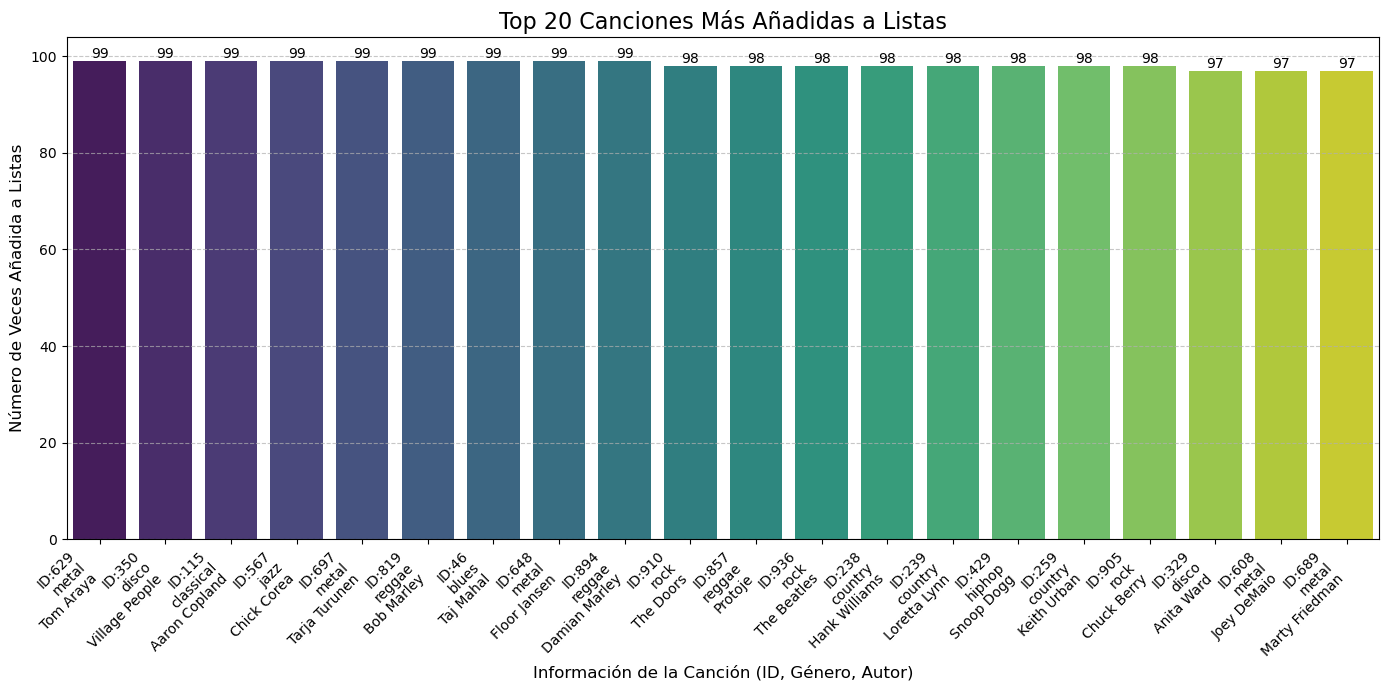

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

top_songs_df = listas_por_cancion.head(20).reset_index()

top_songs_df['combined_label'] = top_songs_df.apply(
    lambda row: f"ID:{row['id_cancion']}\n{row['genero']}\n{row['autor']}", axis=1)

plt.figure(figsize=(14, 7))

ax = sns.barplot(x='combined_label', y='count', data=top_songs_df, palette='viridis', hue='combined_label', legend=False)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.title('Top 20 Canciones Más Añadidas a Listas', fontsize=16)
plt.xlabel('Información de la Canción (ID, Género, Autor)', fontsize=12)
plt.ylabel('Número de Veces Añadida a Listas', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

En el Top 20 de canciones con mayor presencia en listas se observa una distribución bastante variada de géneros musicales. Aparecen canciones de géneros como blues, metal, disco, reggae, classical, jazz, rock, hip-hop y country, lo que indica que las canciones más añadidas a listas no pertenecen a un único estilo musical dominante.

También destaca que las diferencias entre las primeras posiciones son muy reducidas, ya que muchas canciones aparecen entre 97 y 99 veces en listas. Esto sugiere que no existe una única canción que concentre claramente la mayor parte de las apariciones, sino un grupo amplio de canciones con una presencia muy similar.

In [19]:
top_canciones_listas_info = (
    df_listas_eda
    .groupby(['id_cancion', 'genero', 'disco', 'autor'], dropna=False)
    .size()
    .reset_index(name='num_listas')
    .sort_values('num_listas', ascending=False)
)

display(top_canciones_listas_info.head(20))

,id_cancion,genero,disco,autor,num_listas
628,629,metal,metal0,Tom Araya,99
349,350,disco,disco17,Village People,99
114,115,classical,classical13,Aaron Copland,99
566,567,jazz,jazz17,Chick Corea,99
696,697,metal,metal1,Tarja Turunen,99
818,819,reggae,reggae19,Bob Marley,99
45,46,blues,blues7,Taj Mahal,99
647,648,metal,metal13,Floor Jansen,99
893,894,reggae,reggae10,Damian Marley,99
909,910,rock,rock8,The Doors,98


In [20]:
# Número de apariciones en listas agrupadas por género, disco y autor.
listas_por_genero = (
    df_listas_eda[['genero','disco','autor']]
    .value_counts()
    .reset_index()
)

listas_por_genero.columns = ['genero','disco','autor', 'num_apariciones_en_listas']

display(listas_por_genero)

,genero,disco,autor,num_apariciones_en_listas
0,country,country9,Reba McEntire,193
1,hiphop,hiphop12,J. Cole,188
2,hiphop,hiphop0,Biggie Smalls,178
3,country,country2,Loretta Lynn,166
4,disco,disco16,Gibson Brothers,161
...,...,...,...,...
929,metal,metal2,James Hetfield,1
930,country,country17,Rascal Flatts,1
931,pop,pop4,Miley Cyrus,1
932,blues,blues3,Willie Dixon,1


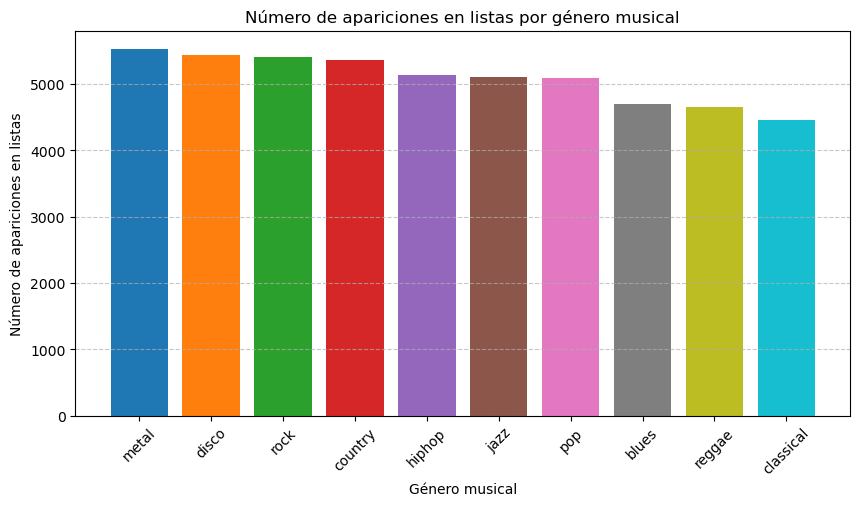

In [21]:
import matplotlib.pyplot as plt

# Número de apariciones en listas agrupadas por género
listas_por_genero = (
    df_listas_eda['genero']
    .value_counts()
    .rename_axis('genero')
    .reset_index(name='num_apariciones_en_listas')
)

# Creamos un color distinto para cada género
colores = plt.cm.tab10.colors[:len(listas_por_genero)]

plt.figure(figsize=(10, 5))

plt.bar(
    listas_por_genero['genero'],
    listas_por_genero['num_apariciones_en_listas'],
    color=colores
)

plt.title('Número de apariciones en listas por género musical')
plt.xlabel('Género musical')
plt.ylabel('Número de apariciones en listas')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

In [22]:
# Media de apariciones en listas por canción dentro de cada género
resumen_genero_listas = (
    df_listas_eda
    .groupby('genero')
    .agg(
        total_apariciones=('id_cancion', 'count'),
        canciones_unicas=('id_cancion', 'nunique')
    )
    .reset_index()
)

resumen_genero_listas['media_apariciones_por_cancion'] = (
    resumen_genero_listas['total_apariciones'] /
    resumen_genero_listas['canciones_unicas']
).round(2)

resumen_genero_listas = resumen_genero_listas.sort_values(
    'media_apariciones_por_cancion',
    ascending=False
)

display(resumen_genero_listas)

,genero,total_apariciones,canciones_unicas,media_apariciones_por_cancion
6,metal,5533,100,55.33
3,disco,5442,100,54.42
9,rock,5417,100,54.17
2,country,5360,100,53.60
4,hiphop,5141,100,51.41
5,jazz,5105,100,51.05
7,pop,5098,100,50.98
0,blues,4706,100,47.06
8,reggae,4663,100,46.63
1,classical,4458,100,44.58


In [23]:
# Top 10 discos con mayor presencia en listas
discos_mas_listas = (
    df_listas_eda
    .groupby('disco', dropna=False)
    .size()
    .reset_index(name='num_apariciones_en_listas')
    .sort_values('num_apariciones_en_listas', ascending=False)
)

print("Top 10 discos con mayor presencia en listas:")
display(discos_mas_listas.head(10))

Top 10 discos con mayor presencia en listas:


,disco,num_apariciones_en_listas
52,country2,694
139,metal9,683
184,rock12,622
113,jazz3,599
38,classical8,579
131,metal19,578
195,rock5,576
118,jazz8,574
51,country19,548
148,pop16,542


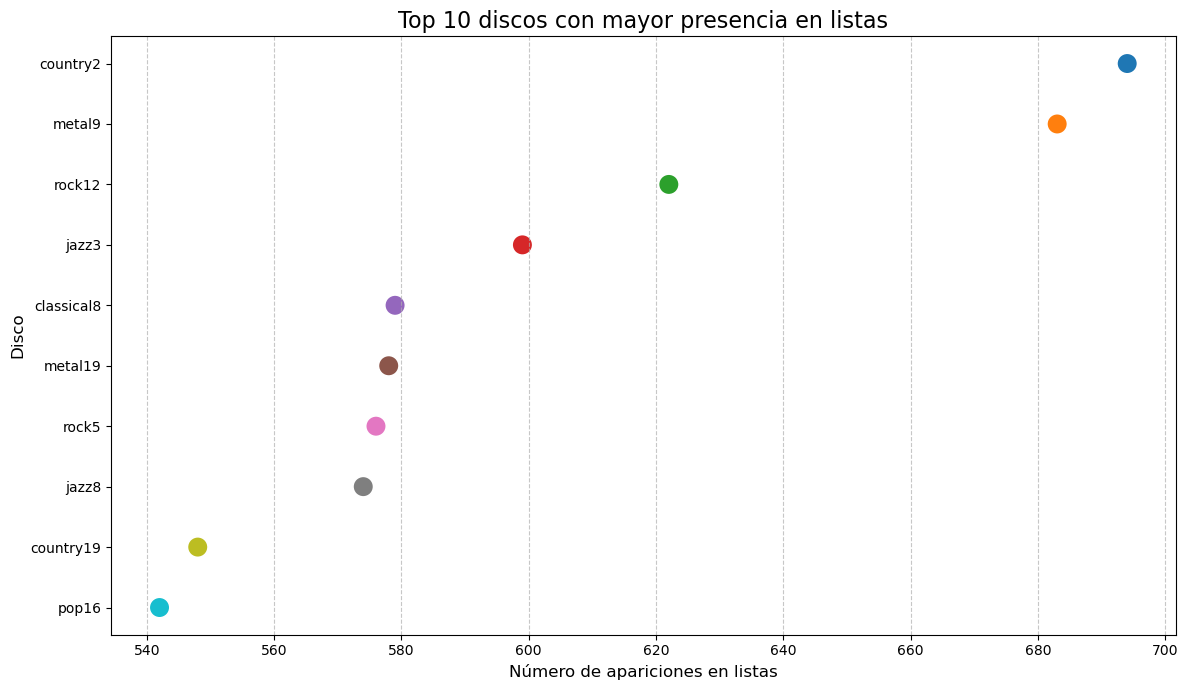

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionamos el Top 10 de discos con mayor presencia en listas
top10_discos = discos_mas_listas.head(10).copy()

colores = [
    '#1f77b4',  # azul
    '#ff7f0e',  # naranja
    '#2ca02c',  # verde
    '#d62728',  # rojo
    '#9467bd',  # morado
    '#8c564b',  # marrón
    '#e377c2',  # rosa
    '#7f7f7f',  # gris
    '#bcbd22',  # oliva
    '#17becf'   # cian
]

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=top10_discos,
    x='num_apariciones_en_listas',
    y='disco',
    hue='disco',
    palette=colores,
    s=220,
    legend=False
)

plt.title('Top 10 discos con mayor presencia en listas', fontsize=16)
plt.xlabel('Número de apariciones en listas', fontsize=12)
plt.ylabel('Disco', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

Este gráfico aporta una lectura complementaria al ranking por canciones individuales. Mientras que el Top 20 permite detectar pistas concretas con alta presencia en listas, el análisis por disco agrupa esas apariciones según el disco al que pertenece cada canción.

De esta forma, podemos observar qué discos concentran un mayor número de canciones añadidas a listas por los usuarios. No significa que los usuarios hayan añadido el disco completo, sino que varias canciones pertenecientes a esos discos aparecen con frecuencia dentro de las listas analizadas.

In [25]:
# Top 10 autores con mayor presencia en listas
autores_mas_listas = (
    df_listas_eda['autor']
    .value_counts()
    .reset_index()
)

autores_mas_listas.columns = ['autor', 'num_apariciones_en_listas']

display(autores_mas_listas.head(10))

,autor,num_apariciones_en_listas
0,Loretta Lynn,668
1,Eric Clapton,602
2,Sharon den Adel,467
3,Nicki Minaj,465
4,Floor Jansen,461
5,Joey DeMaio,448
6,Chuck Berry,438
7,J. Cole,423
8,Muddy Waters,375
9,Run-D.M.C.,373


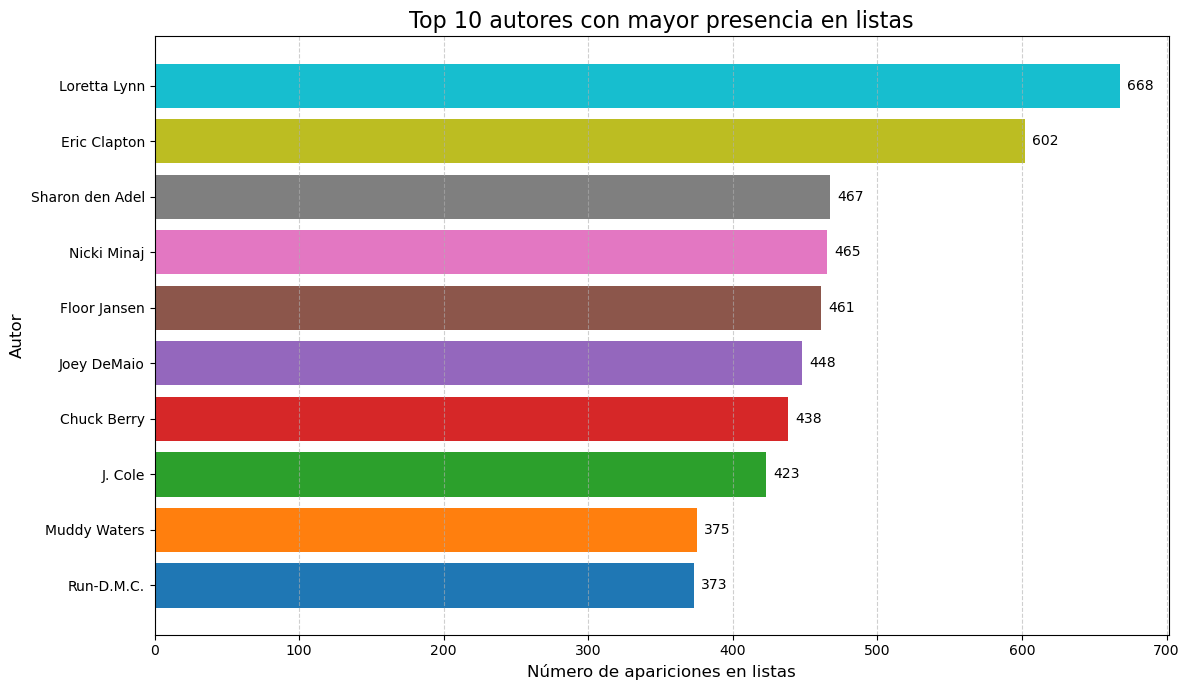

In [26]:
import matplotlib.pyplot as plt

# Top 10 autores con mayor presencia en listas
autores_mas_listas = (
    df_listas_eda['autor']
    .value_counts()
    .reset_index()
)

autores_mas_listas.columns = ['autor', 'num_apariciones_en_listas']

top10_autores = autores_mas_listas.head(10).sort_values(
    'num_apariciones_en_listas',
    ascending=True
)

# Colores diferentes para cada autor
colores = plt.cm.tab10.colors[:len(top10_autores)]

plt.figure(figsize=(12, 7))

bars = plt.barh(
    top10_autores['autor'],
    top10_autores['num_apariciones_en_listas'],
    color=colores
)

plt.title('Top 10 autores con mayor presencia en listas', fontsize=16)
plt.xlabel('Número de apariciones en listas', fontsize=12)
plt.ylabel('Autor', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Añadimos el valor al final de cada barra
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 5,
        bar.get_y() + bar.get_height() / 2,
        int(width),
        va='center'
    )

plt.tight_layout()
plt.show()

Gracias a este último gráfico identificamos qué autores tienen mayor presencia en la organización musical de los usuarios. No significa necesariamente que sean los autores más escuchados o los más valorados, pero sí que sus canciones aparecen con más frecuencia dentro de listas personales, lo que puede indicar cierto interés por incluir sus canciones dentro de selecciones musicales concretas.

# Conclusiones del Análisis de Listas


El análisis de la tabla de listas permite observar qué canciones aparecen con mayor frecuencia dentro de las listas creadas por los usuarios. Este dato puede interpretarse como una señal de interés, organización o intención de escucha, ya que una canción añadida a una lista probablemente se guarda para ser escuchada de nuevo o para formar parte de una selección concreta.

Al enriquecer la tabla con información de canciones, el análisis no se limita únicamente al identificador de la canción, sino que también permite estudiar qué géneros, discos y autores tienen mayor presencia dentro de las listas. Esto aporta una visión más útil desde el punto de vista de negocio, ya que permite detectar patrones de consumo y contenidos con mayor recurrencia dentro de la plataforma.

En el análisis por género se aprecia una distribución variada, aunque algunos géneros concentran un mayor número de apariciones en listas. Además, la media de apariciones por canción permite comparar los géneros de forma más equilibrada, evitando que destaquen únicamente aquellos que tienen más canciones disponibles.

Por último, el análisis de discos con mayor presencia en listas puede ser útil para identificar agrupaciones musicales que generan más interés entre los usuarios. En conjunto, la tabla de listas aporta información complementaria a la tabla de favoritos, ya que no refleja únicamente una preferencia explícita, sino también la forma en la que los usuarios organizan y agrupan la música dentro de la plataforma.